# Figure: Segmentation Mask Overlay

Overlays the exclusive anatomical segmentation masks (lung / soft-tissue / bone)
on sample input images from the experiment.

Mask channel order follows `MASK_GROUPS`: `['lung', 'soft', 'bone']`.

**Requires:** `nb_run.ipynb`

Output: `build/segmentation_masks.png`

In [1]:
%%capture
import os, subprocess, sys

IN_COLAB = "COLAB_GPU" in os.environ or "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")

    REPO = "/content/drive/MyDrive/Reconstruction"  # <-- repo location on Drive

    os.chdir(f"{REPO}/figures")
else:
    REPO = os.path.abspath("..")

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", REPO])
if REPO not in sys.path:
    sys.path.insert(0, REPO)



[notice] A new release of pip is available: 25.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import sys, os, glob, joblib

import matplotlib.pyplot as plt
from chest_xray_sim.visualization import plot_segmentation_overlay

def load_results(results_dir="results"):
    hits = sorted(glob.glob(f"{results_dir}/*/imgs.joblib"))
    if not hits:
        raise FileNotFoundError(f"No results in '{results_dir}'. Run nb_run.ipynb first.")
    d = os.path.dirname(hits[-1])
    print(f"Loading from {d}")
    return {
        "imgs":       joblib.load(f"{d}/imgs.joblib"),
        "masks":      joblib.load(f"{d}/masks.joblib"),
        "seg_labels": joblib.load(f"{d}/seg_labels.joblib"),
    }

/Volumes/T7/projs/thesis/.venv_nb/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
r = load_results()
imgs, masks, seg_labels = r["imgs"], r["masks"], r["seg_labels"]
imgs, masks, seg_labels = imgs.squeeze(), masks, seg_labels
print(f"Image shape: {imgs[0].shape}, masks: {masks[0].shape}, labels: {seg_labels}")

Loading from results/a8107d9
Image shape: (512, 512), masks: (3, 512, 512), labels: ['lung', 'soft', 'bone']


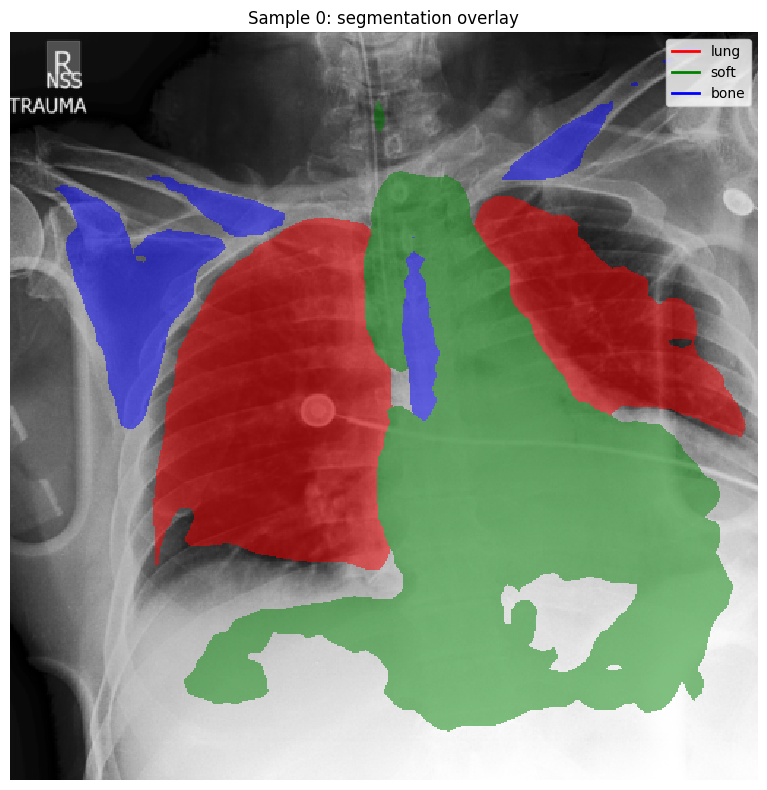

In [9]:
# Single sample
IDX = 0
fig, ax = plot_segmentation_overlay(imgs[IDX], masks[IDX], seg_labels)
ax.set_title(f"Sample {IDX}: segmentation overlay")
fig.tight_layout()
fig.savefig("build/segmentation_masks.png", bbox_inches="tight")
plt.show()

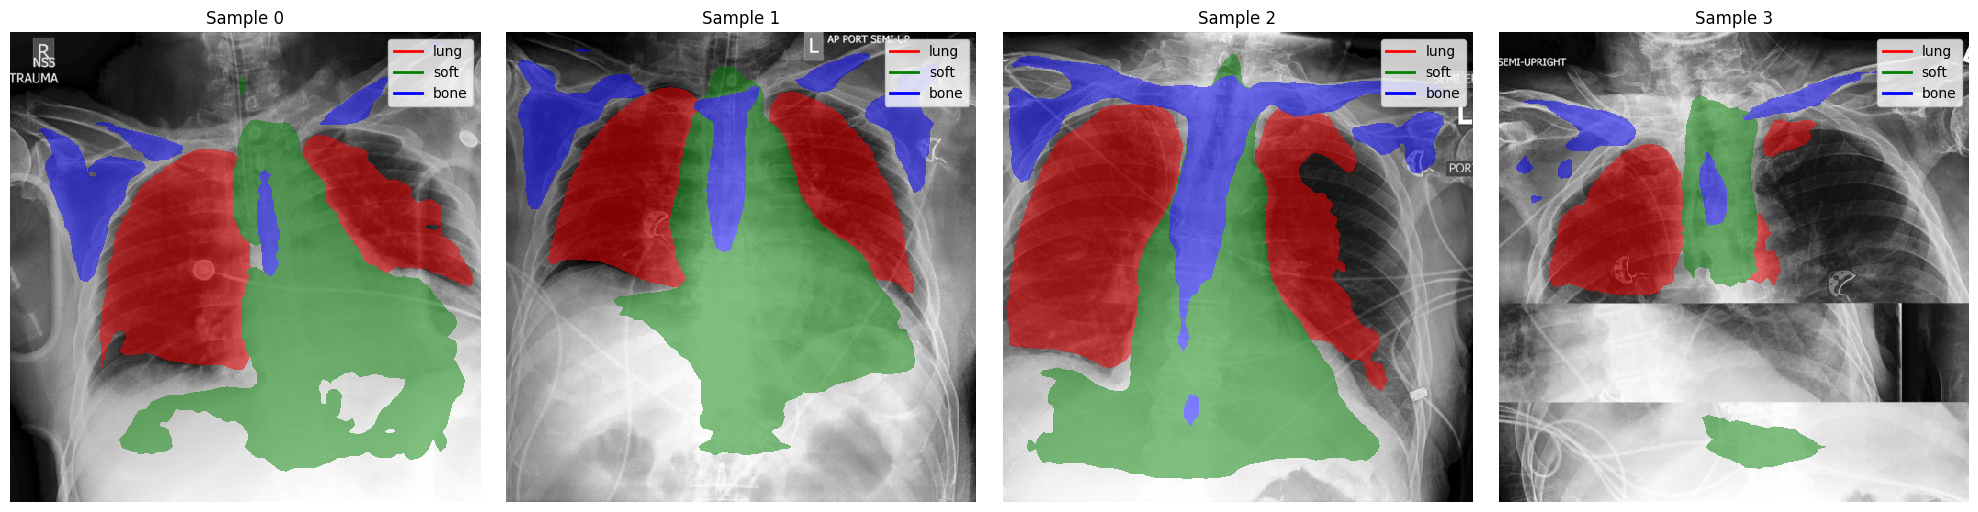

In [10]:
# Grid of 4 samples
N = min(4, imgs.shape[0])
fig, axes = plt.subplots(1, N, figsize=(5 * N, 5))
if N == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    plot_segmentation_overlay(imgs[i], masks[i], seg_labels, ax=ax)
    ax.set_title(f"Sample {i}")

fig.tight_layout()
fig.savefig("build/segmentation_masks_grid.png", bbox_inches="tight")
plt.show()